In [270]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency

In [271]:
df_asli = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')
kolom = ['tenure', 'MonthlyCharges', 'TotalCharges', 'SeniorCitizen']
df = df_asli[kolom + ['Churn']].copy()

## Tentang Dataset

**Telco Customer Churn** (IBM sample dataset, tersedia di Kaggle) berisi data **7.043 pelanggan** sebuah perusahaan telekomunikasi fiktif di California. Tujuan umumnya: memahami dan memprediksi pelanggan mana yang **berhenti berlangganan (churn)**. Dataset asli punya 21 kolom; di notebook ini hanya dipakai **4 fitur + target**.

### Makna kolom

| Kolom | Tipe | Arti | Rentang / nilai |
|---|---|---|---|
| `tenure` | numerik (int) | Lama pelanggan berlangganan, dalam **bulan** | 0 – 72 (median 29) |
| `MonthlyCharges` | numerik (float) | Tagihan per bulan saat ini (USD) | 18,25 – 118,75 (median 70,35) |
| `TotalCharges` | **teks (object)** → perlu dikonversi | Total tagihan yang sudah dibayar selama berlangganan (USD) | 18,8 – 8.684,8 |
| `SeniorCitizen` | biner (0/1) | Apakah pelanggan lansia (≥ 65 tahun) | 0 = bukan (≈84%), 1 = lansia (≈16%) |
| `Churn` | kategorikal (`Yes`/`No`) | **Target**: pelanggan berhenti dalam bulan terakhir | Yes ≈ 26,5%, No ≈ 73,5% |

### Hal yang perlu diperhatikan

1. **`TotalCharges` terbaca sebagai string**, karena ada **11 baris berisi spasi kosong (`" "`)**. Semua baris itu punya `tenure = 0` (pelanggan baru yang belum ditagih). Konversi dengan `pd.to_numeric(df['TotalCharges'], errors='coerce')`, lalu putuskan: isi dengan 0 atau hapus barisnya.
2. **Target tidak seimbang (imbalanced)**: hanya ±26,5% yang churn. Akurasi saja bisa menyesatkan; perhatikan juga *recall*, *precision*, *F1*, atau ROC-AUC, dan pertimbangkan `stratify=y` saat `train_test_split`.
3. **`Churn` masih berupa teks**: ubah ke 0/1 (mis. `df['Churn'].map({'No': 0, 'Yes': 1})`) sebelum modeling.
4. **Multikolinearitas**: `TotalCharges` ≈ `tenure × MonthlyCharges`, dengan korelasi `tenure`–`TotalCharges` ≈ 0,83. Perlu diwaspadai untuk model linear (mis. Logistic Regression).
5. **`SeniorCitizen` sudah 0/1**, jadi meskipun bertipe int, ia sebenarnya **kategorikal**. Untuk uji hubungan dengan `Churn`, gunakan **chi-square** (`chi2_contingency`), bukan korelasi Pearson.
6. **Skala fitur berbeda jauh** (`TotalCharges` ribuan, `tenure` puluhan), sehingga perlu *scaling* untuk model berbasis jarak/gradien (KNN, SVM, Logistic Regression).

### Gambaran awal pola churn
- Pelanggan yang churn rata-rata **tenure lebih pendek** (≈18 bulan vs ≈38 bulan).
- Pelanggan yang churn rata-rata **MonthlyCharges lebih tinggi** (≈74 vs ≈61 USD).
- Tingkat churn **lansia ≈ 42%**, jauh di atas non-lansia (≈ 24%).

## Analisis Awal Keseluruhan

In [272]:
## Tampilan data
df.head()

,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
0,1,29.85,29.85,0,No
1,34,56.95,1889.5,0,No
2,2,53.85,108.15,0,Yes
3,45,42.30,1840.75,0,No
4,2,70.70,151.65,0,Yes


- Baris 0 punya tenure = 1 dan TotalCharge = MonthlyCharges. Ini menandakan TotalCharge = Tenure x MonthlyCharges

In [273]:
## .info()
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   tenure          7043 non-null   int64  
 1   MonthlyCharges  7043 non-null   float64
 2   TotalCharges    7043 non-null   str    
 3   SeniorCitizen   7043 non-null   int64  
 4   Churn           7043 non-null   str    
dtypes: float64(1), int64(2), str(2)
memory usage: 275.2 KB


- kolom TotalCharges tipe datanya salah (str -> float)
- senior citizen dan Churn ubah jadi kategori
- Semua kolom punya 7043 non-null. Jadi tidak ada NaN di kelima kolom tersebut

In [274]:
## Analisis awal
print(f"Jumlah baris dan kolom: {df.shape}")
print(f"Jumlah baris duplikat: {df.duplicated().sum()}")

display(df.isna().sum())

Jumlah baris dan kolom: (7043, 5)
Jumlah baris duplikat: 155


tenure            0
MonthlyCharges    0
TotalCharges      0
SeniorCitizen     0
Churn             0
dtype: int64

- Ada 7043 baris dan 5 kolom (4 fitur dan 1 target)
- Ada 155 baris duplikat (dugaan awal)
- Tidak ada missing value 

In [275]:
## Cek duplikat beneran?
print(f"Data beneran duplikat? {df_asli[df.duplicated()].duplicated().sum()}")

Data beneran duplikat? 0


Data tidak beneran duplikat, 155 baris hanya karena data dipotong menjadi 5 kolom saja

,Jumlah,Persentase (%)
Churn,,
No,5174,73.46
Yes,1869,26.54


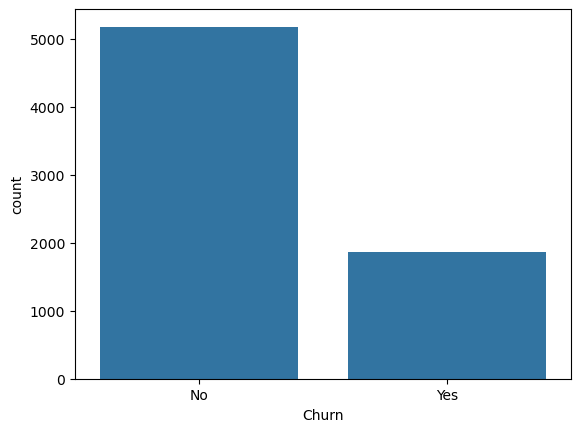

<Figure size 640x480 with 0 Axes>

In [276]:
## Distribusi Target

vc = pd.DataFrame({
    'Jumlah': df['Churn'].value_counts(),
    'Persentase (%)': df['Churn'].value_counts(normalize=True).mul(100).round(2)
})
display(vc)

sns.countplot(data=df, x='Churn')

plt.show()
plt.tight_layout()

- Kelas target tidak seimbang
- No di 5174 (73.46%) dan Yes di 1869 (26.54%)
- Perbandingannya No dan Yes sekitar 3 : 1

## Analisis Per Kolom

### Total Charges

In [277]:
## Cek missing value

spasi_kosong = df[df['TotalCharges'].str.strip() == '']
print(f"Jumlah data berisi spasi: {spasi_kosong.shape[0]}")
display(spasi_kosong)

Jumlah data berisi spasi: 11


,tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
488,0,52.55,,0,No
753,0,20.25,,0,No
936,0,80.85,,0,No
1082,0,25.75,,0,No
1340,0,56.05,,0,No
3331,0,19.85,,0,No
3826,0,25.35,,0,No
4380,0,20.00,,0,No
5218,0,19.70,,0,No
6670,0,73.35,,0,No


- Ada 11 baris berisi spasi, semuanya Tenure 0, SeniorCitizen = 0, Churn = 0
- MonthlyCharges nya bervariasi

## Preprocessing data

In [278]:
## Mengisi Nilai kosong Total Charges dengan nol
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

print(f"Jumlah data berisi spasi setelah diisi: {(df['TotalCharges'].astype(str).str.strip() == '').sum()}")

Jumlah data berisi spasi setelah diisi: 0


- Setelah diisi, 0 baris berisi spasi

In [279]:
## Ubah tipe data TotalCharges menjadi numerik
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')
df.dtypes

tenure              int64
MonthlyCharges    float64
TotalCharges      float64
SeniorCitizen       int64
Churn                 str
dtype: object

- TotalCharges sudah menjadi float64

In [280]:
## Mengubah tipe data SeniorCitizen menjadi kategorikal
df['SeniorCitizen'] = df['SeniorCitizen'].astype('category')
df.dtypes

tenure               int64
MonthlyCharges     float64
TotalCharges       float64
SeniorCitizen     category
Churn                  str
dtype: object

- SeniorCitizen sudah menjadi tipe data category

## Analisis Setelah Preprocessing

In [281]:
## Describe

print(f"Describe data kategorikal:")
display(df.select_dtypes(exclude='number').describe())

print(f"Describe data numerik:")
display(df.describe())

print(f"Unique values in 'SeniorCitizen': {df['SeniorCitizen'].unique().tolist()}")
print(f"Unique values in 'Churn': {df['Churn'].unique().tolist()}")

Describe data kategorikal:


,SeniorCitizen,Churn
count,7043,7043
unique,2,2
top,0,No
freq,5901,5174


Describe data numerik:


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2279.734304
std,24.559481,30.090047,2266.794470
min,0.000000,18.250000,0.000000
25%,9.000000,35.500000,398.550000
50%,29.000000,70.350000,1394.550000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000


Unique values in 'SeniorCitizen': [0, 1]
Unique values in 'Churn': ['No', 'Yes']


Describe Data Kategorikal
- SeniroCitizen dan Churn masing masing memiliki 7043 data dan 2 nilai unik
- SeniorCitizen: nilai terbanyak 0 dengan 5901 baris. Sisanya 1.142 baris lansia, sekitar 16%
- Churn: nilai terbanyak No dengan 5174 baris

Describe Data Numerik
- Ketiga kolom numerik punya 7043 baris dan tidak ada nilai negatif (min >= 0)
- tenure 0 - 72 bulan, mean 32.37, median 29.25%
- MonthlyCharges: 18,25–118,75, mean 64,76 < median 70,35.
- TotalCharges: 0–8.684,80, mean 2.279,73, jauh di atas median 1.394,55. Std-nya (2.266,79) hampir sama besar dengan mean, jadi sebarannya sangat lebar.
- Skala ketiga kolom berbeda jauh: puluhan, ratusan, dan ribuan.

Nilai Unik
- SeniorCitizen hanya berisi [0, 1].
- Churn hanya berisi ['No', 'Yes'].
- Jadi tidak ada label yang salah atau tidak konsisten pada kolom kategorik

tenure: batas [-60.00, 124.00], outlier = 0
MonthlyCharges: batas [-46.02, 171.38], outlier = 0
TotalCharges: batas [-4683.52, 8868.67], outlier = 0


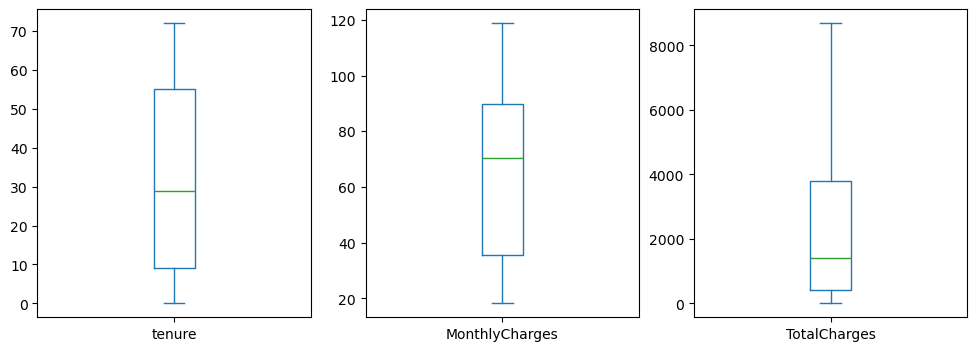

In [282]:
## Outlier
for c in ['tenure', 'MonthlyCharges', 'TotalCharges']:
    q1, q3 = df[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    bawah, atas = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    n = ((df[c] < bawah) | (df[c] > atas)).sum()
    print(f"{c}: batas [{bawah:.2f}, {atas:.2f}], outlier = {n}")

df[['tenure', 'MonthlyCharges', 'TotalCharges']].plot(kind='box', subplots=True,
                                                      layout=(1, 3), figsize=(12, 4))
plt.show()


## Informasi dan Interpretasi

### A. Fakta yang diketahui

**Struktur dan kualitas data (sebelum preprocessing)**
1. Data berisi 7.043 baris dan 5 kolom (4 fitur dan 1 target).
2. Pada baris dengan `tenure = 1`, `TotalCharges` sama dengan `MonthlyCharges`.
3. Tipe data awal: `TotalCharges` str, `SeniorCitizen` int64, `Churn` str.
4. Semua kolom memiliki 7.043 non-null; `isna()` menunjukkan 0 missing value.
5. Terdeteksi 155 baris duplikat pada data 5 kolom, tetapi tidak ada duplikat pada data asli.
6. Distribusi target: No 5.174 (73,46%) dan Yes 1.869 (26,54%), perbandingan sekitar 3 : 1.
7. Ada 11 baris `TotalCharges` berisi spasi; semuanya `tenure = 0`, `SeniorCitizen = 0`, dan `Churn = No`, dengan `MonthlyCharges` bervariasi.
8. Kelompok fitur:

| Kolom | Kelompok | Sub-kelompok |
|---|---|---|
| `tenure` | Numerik | Diskrit |
| `MonthlyCharges` | Numerik | Kontinu |
| `TotalCharges` | Numerik | Kontinu |
| `SeniorCitizen` | Kategorik | Nominal |
| `Churn` *(target)* | Kategorik | Nominal |

**Setelah preprocessing**

9. Setelah diisi 0, tidak ada lagi baris `TotalCharges` berisi spasi; `TotalCharges` bertipe float64 dan `SeniorCitizen` bertipe category. `Churn` masih bertipe str.
10. Kolom kategorik: `SeniorCitizen` hanya berisi [0, 1], dengan 0 sebanyak 5.901 baris dan 1 sebanyak 1.142 baris (±16%). `Churn` hanya berisi ['No', 'Yes'].
11. Ketiga kolom numerik memiliki 7.043 data dan tidak ada nilai negatif (min ≥ 0).
12. Statistik deskriptif kolom numerik:

| Kolom | Min–Max | Mean | Median | Std |
|---|---|---|---|---|
| `tenure` | 0–72 | 32,37 | 29 | 24,56 |
| `MonthlyCharges` | 18,25–118,75 | 64,76 | 70,35 | 30,09 |
| `TotalCharges` | 0–8.684,80 | 2.279,73 | 1.394,55 | 2.266,79 |

13. Skala ketiga kolom numerik berbeda jauh (puluhan, ratusan, dan ribuan).
14. Berdasarkan aturan IQR, jumlah outlier pada `tenure`, `MonthlyCharges`, dan `TotalCharges` adalah 0.

### B. Interpretasi
1. `TotalCharges` kemungkinan merupakan akumulasi tagihan bulanan (≈ `tenure × MonthlyCharges`). *(fakta 2)*
2. Tipe data `TotalCharges` salah, karena isinya angka tetapi terbaca sebagai teks. *(fakta 3)*
3. `SeniorCitizen` walaupun berbentuk angka sebenarnya kategori (0/1 hanya label). *(fakta 3, 8)*
4. Missing value tidak terdeteksi oleh `isna()` karena nilai kosong `TotalCharges` berupa spasi, bukan NaN. *(fakta 4, 7)*
5. 155 duplikat bukan duplikat sungguhan; baris-baris itu muncul karena data dipotong menjadi 5 kolom. *(fakta 5)*
6. Kelas target tidak seimbang; pelanggan yang tidak churn sekitar tiga kali lipat yang churn. *(fakta 6)*
7. 11 nilai kosong `TotalCharges` milik pelanggan dengan `tenure = 0`, sehingga total tagihannya memang belum ada. *(fakta 7)*
8. Label pada kolom kategorik valid dan konsisten, dan tidak ada nilai numerik yang tidak masuk akal (negatif). *(fakta 10, 11)*
9. Mayoritas pelanggan bukan lansia; kelompok lansia jauh lebih kecil (±16%). *(fakta 10)*
10. `TotalCharges` miring ke kanan (*right-skewed*): mean jauh di atas median dan std hampir sebesar mean, artinya banyak pelanggan dengan total tagihan kecil dan sedikit dengan total tagihan sangat besar. *(fakta 12)*
11. `MonthlyCharges` sedikit miring ke kiri (mean < median), artinya ada cukup banyak pelanggan dengan tagihan bulanan rendah yang menarik rata-rata ke bawah. *(fakta 12)*
12. Tidak ada nilai ekstrem yang perlu ditangani pada kolom numerik. *(fakta 14)*
13. Perbedaan skala antar kolom numerik dapat memengaruhi model yang sensitif terhadap skala. *(fakta 13)*
14. Secara keseluruhan, data sudah bersih: tipe data benar, tidak ada nilai kosong, tidak ada duplikat sungguhan, label valid, dan tidak ada outlier. *(fakta 9–14)*

### C. Keputusan
| No | Keputusan | Dasar | Status |
|---|---|---|---|
| 1 | Nilai kosong `TotalCharges` diisi 0 | Interpretasi 7 | ✅ Sudah |
| 2 | `TotalCharges` diubah ke float | Interpretasi 2 | ✅ Sudah |
| 3 | Baris duplikat tidak dihapus | Interpretasi 5 | ✅ Sudah |
| 4 | `SeniorCitizen` diubah ke kategori | Interpretasi 3 | ✅ Sudah |
| 5 | Tidak ada baris yang dihapus atau diubah karena outlier | Interpretasi 12 | ✅ Sudah |
| 6 | `Churn` diubah ke kategori (atau di-encode 0/1 saat modeling) | Fakta 9 | ⏳ Belum |
| 7 | Ketidakseimbangan kelas target diperhitungkan saat pembagian data dan evaluasi model | Interpretasi 6 | ⏳ Belum |
| 8 | Fitur numerik di-*scaling* sebelum dipakai pada model yang sensitif terhadap skala | Interpretasi 13 | ⏳ Belum |
| 9 | Lanjut ke analisis hubungan tiap fitur dengan `Churn` | Interpretasi 14 | ⏳ Belum |

## Hasil akhir